In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# # Data Load

In [61]:
df = pd.read_csv("bank_transactions_data_2.csv")
df.shape

(2512, 16)

In [62]:
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


In [63]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   str    
 1   AccountID                2512 non-null   str    
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   str    
 4   TransactionType          2512 non-null   str    
 5   Location                 2512 non-null   str    
 6   DeviceID                 2512 non-null   str    
 7   IP Address               2512 non-null   str    
 8   MerchantID               2512 non-null   str    
 9   Channel                  2512 non-null   str    
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   str    
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance           2512 non-n

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2512.000000,2512.000000,2512.000000,2512.000000,2512.000000
mean,297.593778,44.673965,119.643312,1.124602,5114.302966
std,291.946243,17.792198,69.963757,0.602662,3900.942499
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.885000,27.000000,63.000000,1.000000,1504.370000
50%,211.140000,45.000000,112.500000,1.000000,4735.510000
75%,414.527500,59.000000,161.000000,1.000000,7678.820000
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


# # Data Cleaning

### Messing Value or Duplicate

In [64]:
df.isnull().sum()              # blank value


TransactionID              0
AccountID                  0
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
dtype: int64

In [65]:
df.duplicated().sum()          # duplicate rows 

np.int64(0)

### Date columns ko text se date type mein badalna

In [66]:
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])
df["PreviousTransactionDate"] = pd.to_datetime(df["PreviousTransactionDate"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   TransactionID            2512 non-null   str           
 1   AccountID                2512 non-null   str           
 2   TransactionAmount        2512 non-null   float64       
 3   TransactionDate          2512 non-null   datetime64[us]
 4   TransactionType          2512 non-null   str           
 5   Location                 2512 non-null   str           
 6   DeviceID                 2512 non-null   str           
 7   IP Address               2512 non-null   str           
 8   MerchantID               2512 non-null   str           
 9   Channel                  2512 non-null   str           
 10  CustomerAge              2512 non-null   int64         
 11  CustomerOccupation       2512 non-null   str           
 12  TransactionDuration      2512 non-null   int6

# New Column Create

### Date se month aur day nikalna

In [67]:
df["Month"] = df["TransactionDate"].dt.month
df["DayOfWeek"] = df["TransactionDate"].dt.day_name()

# Age ko groups mein baantna
df["AgeGroup"] = pd.cut(df["CustomerAge"], bins=[17, 30, 45, 60, 100], labels=["18-30", "31-45", "46-60", "60+"])
df[["TransactionDate", "Month", "DayOfWeek", "CustomerAge", "AgeGroup"]].head()

,TransactionDate,Month,DayOfWeek,CustomerAge,AgeGroup
0,2023-04-11 16:29:14,4,Tuesday,70,60+
1,2023-06-27 16:44:19,6,Tuesday,68,60+
2,2023-07-10 18:16:08,7,Monday,19,18-30
3,2023-05-05 16:32:11,5,Friday,26,18-30
4,2023-10-16 17:51:24,10,Monday,26,18-30


In [68]:
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,Month,DayOfWeek,AgeGroup
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08,4,Tuesday,60+
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35,6,Tuesday,60+
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04,7,Monday,18-30
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06,5,Friday,18-30
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39,10,Monday,18-30


# Exploratory Analysis

In [69]:
# Debit or Credit ki count
df["TransactionType"].value_counts()

TransactionType
Debit     1944
Credit     568
Name: count, dtype: int64

In [70]:
# Kaunsa channel zyada use hota hai
df["Channel"].value_counts()

Channel
Branch    868
ATM       833
Online    811
Name: count, dtype: int64

In [71]:
# Average transaction amount, type ke hisaab se
df.groupby("TransactionType")["TransactionAmount"].mean().round(2)

TransactionType
Credit    306.50
Debit     294.99
Name: TransactionAmount, dtype: float64

In [72]:
# Age group ke hisaab se average amount
df.groupby("AgeGroup", observed=True)["TransactionAmount"].mean().round(2)

AgeGroup
18-30    319.24
31-45    279.80
46-60    279.99
60+      303.13
Name: TransactionAmount, dtype: float64

# Channel or transaction type

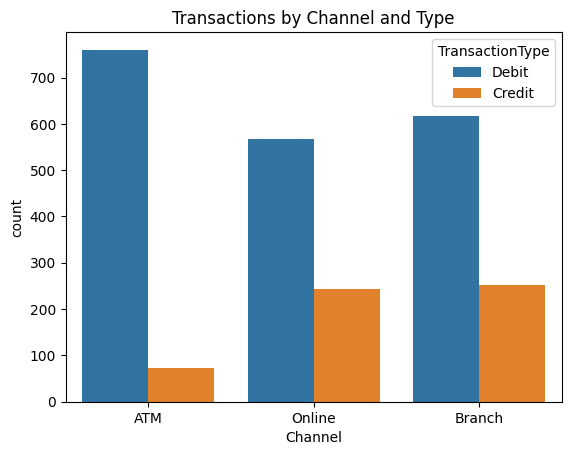

In [73]:
# Channel , TransactionType
sns.countplot(data=df, x="Channel", hue="TransactionType")
plt.title("Transactions by Channel and Type")
plt.show()

# Monthly Trend

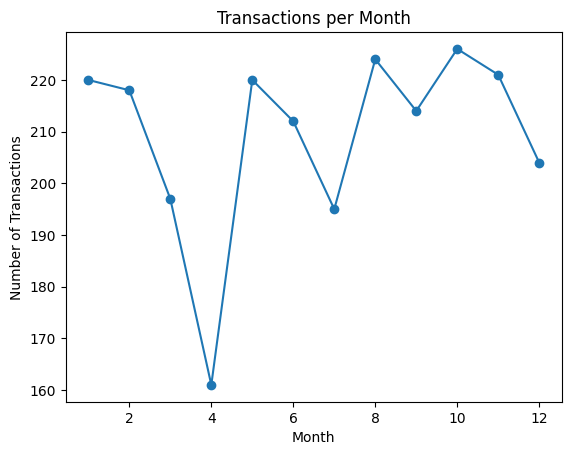

In [74]:
# Month , TransactionID 
monthly = df.groupby("Month")["TransactionID"].count()
monthly.plot(kind="line", marker="o")
plt.title("Transactions per Month")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.show()

# Age group - Avg amount

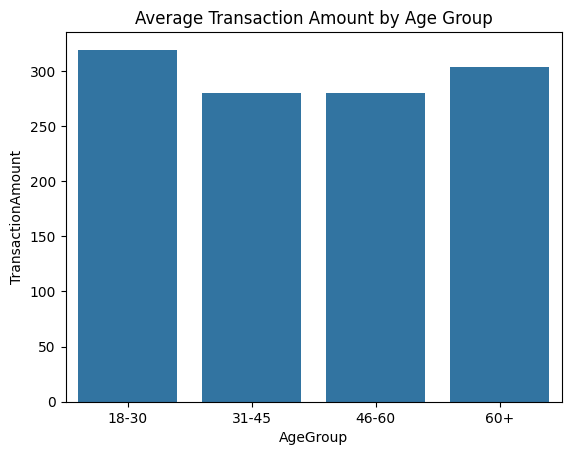

In [75]:
#  AgeGroup , TransactionAmount 
sns.barplot(data=df, x="AgeGroup", y="TransactionAmount", errorbar=None)
plt.title("Average Transaction Amount by Age Group")
plt.show()

# Occupation - avg amount

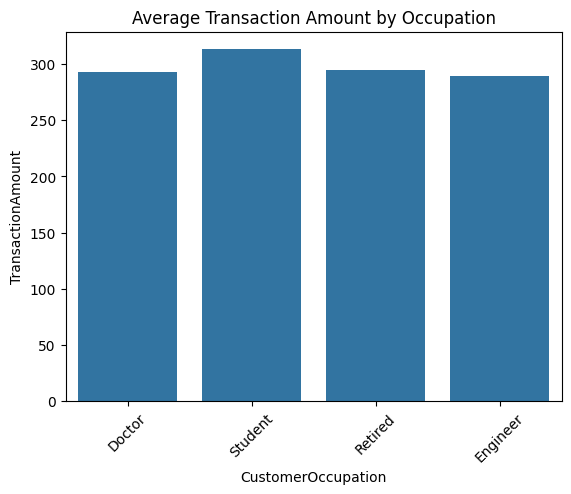

In [76]:
#  CustomerOccupation, TransactionAmount 
sns.barplot(data=df, x="CustomerOccupation", y="TransactionAmount", errorbar=None)
plt.title("Average Transaction Amount by Occupation")
plt.xticks(rotation=45)
plt.show()

# Top 10 location

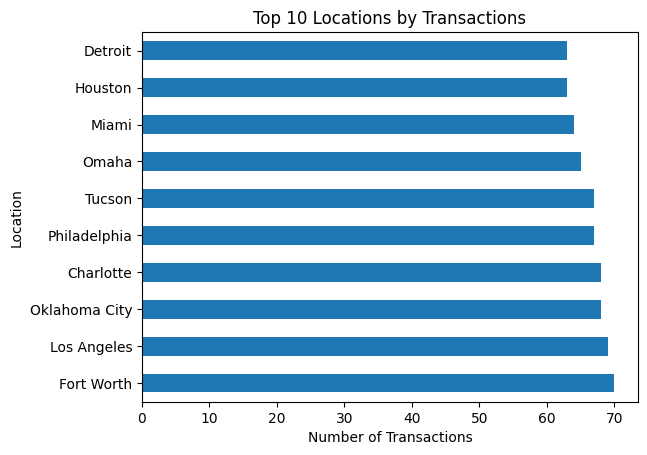

In [77]:
#  Location 
df["Location"].value_counts().head(10).plot(kind="barh")
plt.title("Top 10 Locations by Transactions")
plt.xlabel("Number of Transactions")
plt.show()

# Unusual (big) ammount 

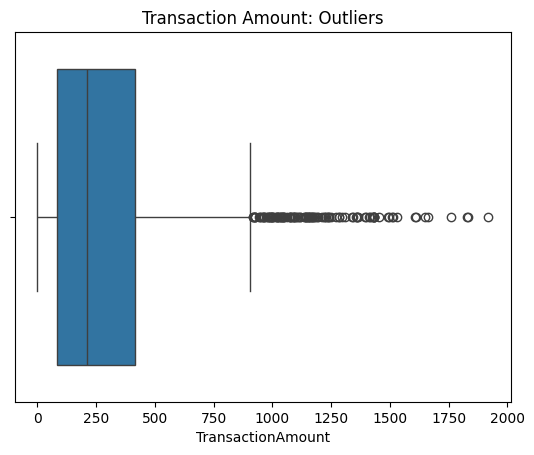

In [78]:
# TransactionAmount 
sns.boxplot(x=df["TransactionAmount"])
plt.title("Transaction Amount: Outliers")
plt.show()

# Login attempts

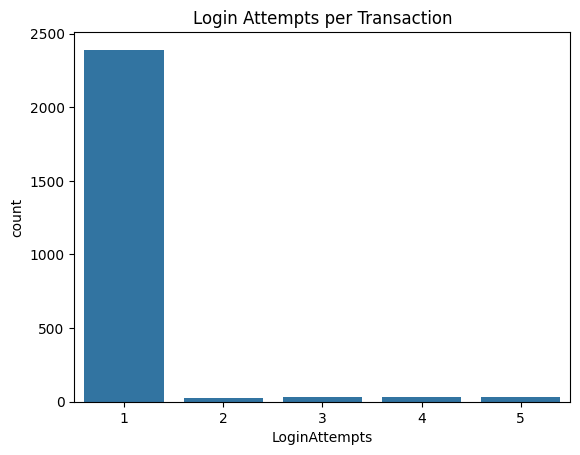

In [79]:
# LoginAttempts (kitni baar login try hua)
sns.countplot(data=df, x="LoginAttempts")
plt.title("Login Attempts per Transaction")
plt.show()

# Outliers count

In [80]:
# IQR method: box ke bahar kitne transactions hain
q1 = df["TransactionAmount"].quantile(0.25)
q3 = df["TransactionAmount"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
unusual = df[df["TransactionAmount"] > upper]
print(len(unusual), upper)

113 913.49125


# Unusual Transaction check

In [81]:
unusual[["TransactionID", "TransactionAmount", "Channel", "Location", "LoginAttempts"]].head(10)

,TransactionID,TransactionAmount,Channel,Location,LoginAttempts
74,TX000075,1212.51,Branch,Indianapolis,1
82,TX000083,922.55,ATM,Detroit,1
85,TX000086,1340.19,Online,Austin,1
110,TX000111,1045.22,ATM,Columbus,1
129,TX000130,1036.66,Branch,San Antonio,1
138,TX000139,997.43,Online,Seattle,1
141,TX000142,1049.92,ATM,Detroit,1
146,TX000147,973.39,Branch,Sacramento,1
176,TX000177,1362.55,ATM,El Paso,1
186,TX000187,1041.88,Online,Jacksonville,1


# login attempts

In [82]:
df["LoginAttempts"].value_counts()

LoginAttempts
1    2390
5      32
4      32
3      31
2      27
Name: count, dtype: int64

In [83]:
df.shape

(2512, 19)

In [84]:
df.columns.tolist()

['TransactionID',
 'AccountID',
 'TransactionAmount',
 'TransactionDate',
 'TransactionType',
 'Location',
 'DeviceID',
 'IP Address',
 'MerchantID',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance',
 'PreviousTransactionDate',
 'Month',
 'DayOfWeek',
 'AgeGroup']

In [85]:
df.to_csv("bank_transactions_clean.csv", index=False)

### # Key Insights

1. **Debit transactions dominate.** 1,944 debit (77.4%) vs 568 credit (22.6%).
2. **Channels are evenly used.** Branch 868 (34.6%), ATM 833 (33.2%), Online 811 (32.3%).
3. **Average amounts are similar.** Credit 306.50 vs debit 294.99, a small difference.
4. **Young customers spend the most.** The 18-30 age group has the highest average transaction (319.24), and students have the highest average amount by occupation.
5. **October is the busiest month** for transactions.
6. **Fort Worth (70 transactions) and Los Angeles lead** by location, but no single city dominates.
7. **113 transactions (4.5%) are unusually large** (above 913.49 by the IQR rule). These need review, but they are not necessarily fraud.
8. **Most logins are clean.** 95.1% of transactions needed 1 login attempt. About 4.9% (122) needed 2 to 5 attempts, which is worth monitoring.



### # Conclusion

- 77% of transactions are debit, and all three channels are used almost equally.
- Customers aged 18-30 and students make the largest average transactions.
- 113 transactions (4.5%) are unusually large and 4.9% needed multiple login attempts; both deserve monitoring.
- The data is likely synthetic and has no fraud label, so findings show patterns, not proof.